# MRI-scans voorbereiden en indelen op aanzicht

Dit notebook filtert afbeeldingen op afmetingen, gebruikt handmatig gelabelde scans om aanzichten te herkennen, vergelijkt twee classificatiemethoden en deelt daarna zowel `Training` als `Testing` in op **axiaal**, **sagittaal** en **coronaal**.

**Invoer:** `./Training/`, `./Testing/` en `./labeled_scans.csv` (kolommen `image`, `choice`).

**Uitvoer:** voorspellingen in CSV en kopieën van de afbeeldingen onder `./Gesorteerd_op_aanzicht/Training/` en `./Gesorteerd_op_aanzicht/Testing/`. De oorspronkelijke bestanden blijven ongewijzigd.

**Belangrijk:** de evaluatie gebruikt een afsplitsing van de handmatig gelabelde trainingsafbeeldingen; de map `Testing` wordt pas na het trainen voorspeld. Dit is een technische aanzichtclassificatie, geen medische diagnose.

## Installatie

Installeert de Python-pakketten die nodig zijn voor het inlezen, bewerken, trainen en beoordelen van het model.

In [1]:
# Stap 0: Installatie
%pip install torch
%pip install torch torchvision
%pip install numpy matplotlib scikit-learn
%pip install torch torchvision pandas pillow scikit-learn

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


## Imports

Laadt de gebruikte bibliotheken.

In [2]:
# Stap 1: Imports
import os
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from pathlib import Path
from torchvision import transforms
from torchvision.datasets import ImageFolder as ImageFolder
from torch.utils.data import Dataset, DataLoader
from sklearn.linear_model import LogisticRegression
from sklearn.semi_supervised import SelfTrainingClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

## Afbeeldingen selecteren

`GefilterdeTumorDataset` doorzoekt de directe submappen van `Training` of `Testing`. Alleen PNG/JPG-afbeeldingen waarvan beide afmetingen minstens 256 pixels zijn, worden meegenomen. De bestaande submapnaam is hier **niet** het aanzichtlabel.

In [3]:
# Stap 3: Afbeeldingen selecteren
class GefilterdeTumorDataset(Dataset):
    def __init__(self, root, min=256, transform=None): 
        # Haal de submappen op als klassen
        self.classes = [
            d for d in os.listdir(root)
            if os.path.isdir(os.path.join(root, d))
        ]

        self.images = []
        self.transform = transform

        for index, group in enumerate(self.classes):
            group_map = os.path.join(root, group)

            for filename in os.listdir(group_map):
                if filename.lower().endswith(('.png', '.jpg', '.jpeg')):
                    pad = os.path.join(group_map, filename)

                    # Controleer de afmetingen
                    with Image.open(pad) as img:
                        width, height = img.size

                    if width >= min and height >= min:
                        self.images.append((pad, index))

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        pad, label = self.images[idx]
        img = Image.open(pad).convert('RGB')

        if self.transform:
            img = self.transform(img)

        return img, label


## Transformaties

Afbeeldingen worden voor de PyTorch-dataloader naar 512 × 512 pixels geschaald en omgezet naar tensors. Het classificatiemodel gebruikt later een aparte 64 × 64-grijswaardenrepresentatie.

In [4]:
# Stap 4: Transformaties
transform = transforms.Compose([
    transforms.Resize((512, 512)),
    transforms.ToTensor()
])

## Trainingsafbeeldingen inladen

Laadt de geselecteerde afbeeldingen uit `./Training`.

In [5]:
# Stap 5: Trainingsafbeeldingen inladen
dataset_train = GefilterdeTumorDataset(root='./Training', min=256, transform=transform)
dataloader_train = DataLoader(dataset_train, batch_size=32, shuffle=True)

print(f"Totaal aantal gefilterde foto's ingeladen: {len(dataset_train)}")

Totaal aantal gefilterde foto's ingeladen: 2559


## Testafbeeldingen inladen

Laadt ook `./Testing` in. Deze map wordt later volledig voorspeld en afzonderlijk ingedeeld.

In [6]:
# Stap 6: Testafbeeldingen inladen
dataset_test = GefilterdeTumorDataset(root='./Testing', min=256, transform=transform)
dataloader_test = DataLoader(dataset_test, batch_size=32, shuffle=True)

print(f"Totaal aantal gefilterde foto's ingeladen: {len(dataset_test)}")

Totaal aantal gefilterde foto's ingeladen: 212


## Handmatige labels uit CSV lezen

`labeled_scans.csv` bevat de kolommen `image` en `choice`. Alleen `Axiaal`, `Sagittaal` en `Coronaal` gelden als handmatige labels; andere afbeeldingen krijgen tijdelijk label `-1`.

In [7]:
# Stap 7: Handmatige labels uit CSV lezen
csv_path = "./labeled_scans.csv"

df = pd.read_csv(csv_path)

# Bestandsnamen uit de image-kolom halen
df["filename"] = df["image"]
df["label"] = df["choice"]

label_mapping = {
    "Axiaal": 0,
    "Sagittaal": 1,
    "Coronaal": 2
}

# Alleen daadwerkelijk gelabelde afbeeldingen
df_labeled = df[df["label"].isin(label_mapping)].copy()

# Numerieke labels toevoegen
df_labeled["label_id"] = df_labeled["label"].map(label_mapping)

print("Aantal CSV-rijen:", len(df))
print("Aantal gelabelde CSV-rijen:", len(df_labeled))

print("\nVerdeling van de labels:")
print(df_labeled["label"].value_counts())

Aantal CSV-rijen: 159
Aantal gelabelde CSV-rijen: 159

Verdeling van de labels:
label
Coronaal     54
Sagittaal    53
Axiaal       52
Name: count, dtype: int64


## Trainingsfeatures maken

Elke geselecteerde trainingsafbeelding wordt omgezet naar een genormaliseerde, afgevlakte 64 × 64-grijswaardenvector (4096 getallen). Labels worden op **bestandsnaam** gekoppeld.

In [8]:
# Stap 8: Trainingsfeatures maken

# Handmatig gelabelde afbeeldingen koppelen aan labels
label_lookup = dict(
    zip(df_labeled["filename"], df_labeled["label_id"])
)

X = [] # Features (pixelwaarden van de afbeeldingen)
y = [] # Labels (het aanzicht)
filenames = []

# Loop door ALLE afbeeldingen
for path, _ in dataset_train.images:

    filename = os.path.basename(path)

    # Bestaand label gebruiken, anders -1
    label = label_lookup.get(filename, -1)

    with Image.open(path) as img:
        img = img.convert("L").resize((64, 64))
        img_array = np.asarray(
            img, dtype=np.float32
        ).flatten() / 255.0

    X.append(img_array)
    y.append(label)
    filenames.append(filename)

X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=int)
filenames = np.array(filenames)

# Controle
print("Totaal aantal afbeeldingen:", len(X))
print("Aantal handmatig gelabeld:", np.sum(y != -1))
print("Aantal ongelabeld:", np.sum(y == -1))

print("\nVerdeling labels:")
print(np.unique(y, return_counts=True))

Totaal aantal afbeeldingen: 2559
Aantal handmatig gelabeld: 142
Aantal ongelabeld: 2417

Verdeling labels:
(array([-1,  0,  1,  2]), array([2417,   44,   50,   48]))


## Eerste experiment: logistische regressie met self-training

Experimenteel model op alle trainingsafbeeldingen. Het model dat uiteindelijk voor de indeling wordt gebruikt, wordt verderop opnieuw getraind met een Random Forest.

## Voorbeelden van handmatig gelabelde scans

Toont maximaal negen willekeurige afbeeldingen met hun bekende aanzicht.

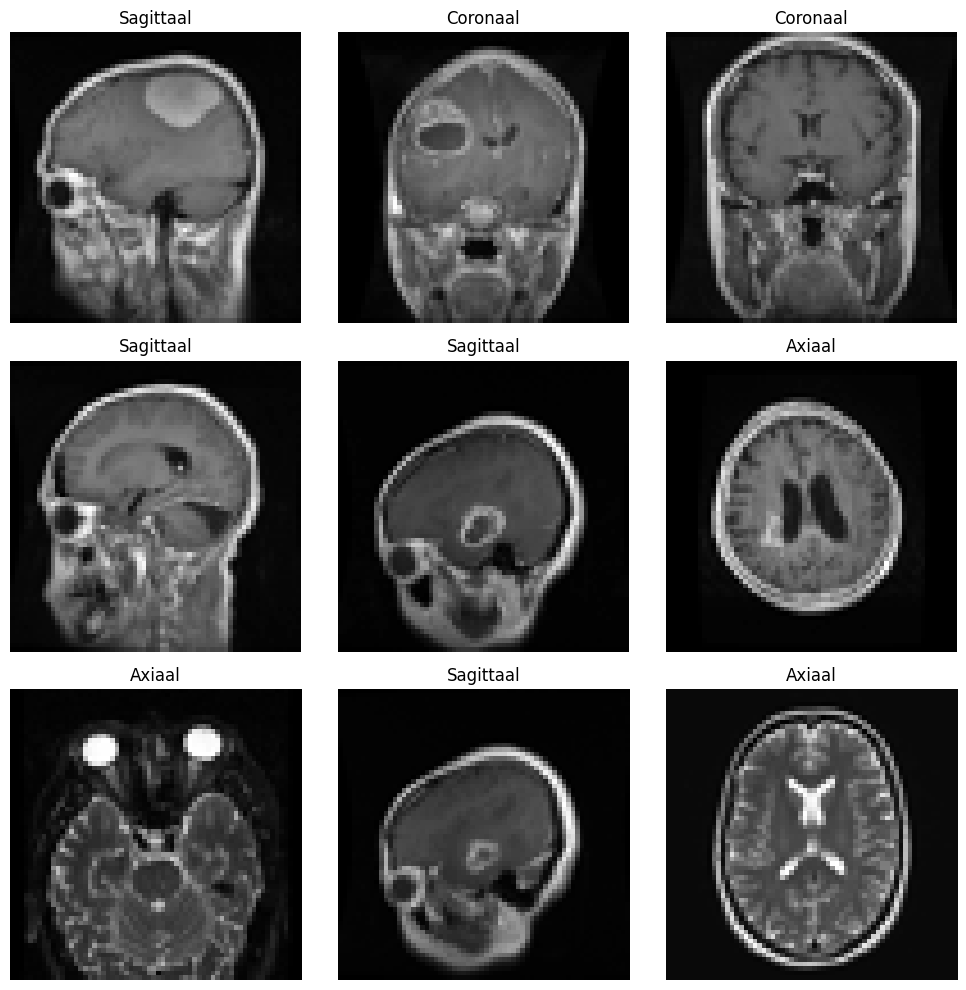

In [9]:
# Stap 10: Voorbeelden van handmatig gelabelde scans

# Alleen gelabelde afbeeldingen
labeled_indices = np.where(y != -1)[0]

label_names = {
    0: "Axiaal",
    1: "Sagittaal",
    2: "Coronaal"
}

# Toon 9 willekeurige gelabelde afbeeldingen
rng = np.random.default_rng(42)

selected = rng.choice(
    labeled_indices,
    size=min(9, len(labeled_indices)),
    replace=False
)

fig, axes = plt.subplots(3, 3, figsize=(10, 10))

for ax, idx in zip(axes.flat, selected):
    ax.imshow(X[idx].reshape(64, 64), cmap="gray")
    ax.set_title(label_names[y[idx]])
    ax.axis("off")

for ax in axes.flat[len(selected):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

## Validatiesplit

Verdeelt alleen de handmatig gelabelde afbeeldingen in 80% training en 20% validatie. Ongelabelde afbeeldingen blijven apart voor self-training. **Dit is niet de map `./Testing`.**

In [10]:
# Stap 11: Validatiesplit

# Alleen handmatig gelabelde afbeeldingen
mask_labeled = y != -1

X_labeled = X[mask_labeled]
y_labeled = y[mask_labeled]

# Ongelabelde afbeeldingen
X_unlabeled = X[y == -1]

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X_labeled,
    y_labeled,
    test_size=0.2,
    random_state=42,
    stratify=y_labeled
)

print("Gelabelde trainingsafbeeldingen:", len(X_train))
print("Testafbeeldingen:", len(X_test))
print("Ongelabelde afbeeldingen:", len(X_unlabeled))

Gelabelde trainingsafbeeldingen: 113
Testafbeeldingen: 29
Ongelabelde afbeeldingen: 2417


## Baseline: Random Forest

Traint een Random Forest op de handmatige trainingslabels en beoordeelt het model op de apart gehouden validatieset.

In [11]:
# Stap 12: Baseline: Random Forest

# Random Forest
base_model = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Trainen met handmatig gelabelde afbeeldingen
base_model.fit(X_train, y_train)

# Voorspellingen op testdata
y_pred = base_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1, 2],
    target_names=["axiaal", "sagittaal", "coronaal"],
    zero_division=0
))

Accuracy: 0.8620689655172413

Classification report:
              precision    recall  f1-score   support

      axiaal       0.89      0.89      0.89         9
   sagittaal       0.90      0.90      0.90        10
    coronaal       0.80      0.80      0.80        10

    accuracy                           0.86        29
   macro avg       0.86      0.86      0.86        29
weighted avg       0.86      0.86      0.86        29



## Semi-supervised Random Forest

Combineert handmatig gelabelde trainingsdata met ongelabelde trainingsdata. Self-training voegt uitsluitend voorspellingen met voldoende zekerheid toe als pseudo-labels.

In [17]:
# Stap 13: Semi-supervised Random Forest

# Combineer trainingsdata met ongelabelde afbeeldingen
X_semi = np.concatenate([X_train, X_unlabeled])

y_semi = np.concatenate([y_train, np.full(len(X_unlabeled), -1)])

# Random Forest
semi_base_model = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Self-training
self_training_clf = SelfTrainingClassifier(
    estimator=semi_base_model,
    threshold=0.90,
    max_iter=20
)

# Trainen
self_training_clf.fit(X_semi, y_semi)

# Resultaten
nieuwe_labels = np.sum(
    (y_semi == -1) &
    (self_training_clf.transduction_ != -1)
)

print("Aantal nieuwe pseudo-labels:", nieuwe_labels)
print("Aantal iteraties:", self_training_clf.n_iter_)
print("Stopreden:", self_training_clf.termination_condition_)

Aantal nieuwe pseudo-labels: 2123
Aantal iteraties: 15
Stopreden: no_change


## Modellen vergelijken

Vergelijkt de baseline met self-training op dezelfde handmatig gelabelde validatieset.

In [13]:
# Stap 14: Modellen vergelijken

# Voorspellingen op dezelfde testset
y_pred_base = base_model.predict(X_test)
y_pred_semi = self_training_clf.predict(X_test)

print("Random Forest accuracy:",
      accuracy_score(y_test, y_pred_base))

print("Self-training accuracy:",
      accuracy_score(y_test, y_pred_semi))

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred_semi,
    labels=[0, 1, 2],
    target_names=["axiaal", "sagittaal", "coronaal"],
    zero_division=0
))

Random Forest accuracy: 0.8620689655172413
Self-training accuracy: 0.7931034482758621

Classification report:
              precision    recall  f1-score   support

      axiaal       0.73      0.89      0.80         9
   sagittaal       0.82      0.90      0.86        10
    coronaal       0.86      0.60      0.71        10

    accuracy                           0.79        29
   macro avg       0.80      0.80      0.79        29
weighted avg       0.80      0.79      0.79        29



## Alle trainings- en testafbeeldingen voorspellen en sorteren

De volgende cellen gebruiken het **getrainde semi-supervised Random Forest** (`self_training_clf`). Voor `Testing` worden dezelfde 64 × 64-grijswaardenfeatures gemaakt als bij training. Voor **beide** mappen worden voorspellingen weggeschreven naar CSV, met het relatieve bronpad zodat dubbele bestandsnamen uit verschillende oorspronkelijke submappen herkenbaar blijven.

De sorteeractie leest deze CSV-bestanden en **kopieert** de originele afbeeldingen naar aparte mappen voor `axiaal`, `sagittaal` en `coronaal`. Ook handmatig gelabelde trainingsafbeeldingen krijgen hier een modelvoorspelling, zodat de werkwijze voor beide datasets gelijk is. De originele bestanden worden niet verplaatst of verwijderd.

**Let op:** alleen afbeeldingen die aan de eerdere minimale afmeting voldoen, worden meegenomen. De map `Testing` wordt voor de voorspelling niet gebruikt om het model te trainen.

In [14]:
# Zelfde preprocessing als tijdens de training van het classificatiemodel.
def make_feature(paths):
    features = []
    for path in paths:
        with Image.open(path) as image:
            grey = image.convert("L").resize((64, 64))
            features.append(np.asarray(grey, dtype=np.float32).flatten() / 255.0)
    return np.asarray(features, dtype=np.float32).reshape(-1, 64 * 64)

# Gebruik de al gefilterde paden uit de twee datasets. 
# Het relatieve pad voorkomt verwarring bij gelijke bestandsnamen in verschillende submappen.
predict_csvs = {}
for datasetname, dataset in (("Training", dataset_train), ("Testing", dataset_test)):
    rootdirectory = Path(datasetname)
    paths = [Path(path) for path, _ in dataset.images]

    if not paths:
        print(f"{datasetname}: geen geschikte afbeeldingen gevonden; overgeslagen.")
        continue

    features = make_feature(paths)
    predicted_ids = self_training_clf.predict(features)
    table = pd.DataFrame({
        "image": [str(path.relative_to(rootdirectory)) for path in paths],
        "predicted_view": [label_names[int(label)] for label in predicted_ids],
    })

    csv_path = Path(f"predicted_view{datasetname.lower()}.csv")
    table.to_csv(csv_path, index=False)
    predict_csvs[datasetname] = csv_path

    # check prints
    print(f"{datasetname}: {len(table)} voorspellingen opgeslagen in {csv_path}")
    print(table["predicted_view"].value_counts().to_string())

Training: 2559 voorspellingen opgeslagen in predicted_viewtraining.csv
predicted_view
Sagittaal    1121
Axiaal        776
Coronaal      662
Testing: 212 voorspellingen opgeslagen in predicted_viewtesting.csv
predicted_view
Axiaal       147
Sagittaal     40
Coronaal      25


### Afbeeldingen naar mappen per aanzicht kopiëren

De CSV is leidend voor de indeling. De uitvoerstructuur wordt bijvoorbeeld `Sorted/Testing/axiaal/...`. De oorspronkelijke submapstructuur blijft **binnen** de aanzichtmap behouden om overschrijven bij gelijke bestandsnamen te vermijden. Opnieuw uitvoeren werkt de kopieën bij, maar verwijdert geen oude uitvoerbestanden.

In [15]:
outputmap = Path("Sorted")
valid_views = {"axiaal", "sagittaal", "coronaal"}

for datasetname, csv_path in predict_csvs.items():

    rootdirectory = Path(datasetname).resolve()
    table = pd.read_csv(csv_path)

    # Maak alle drie de aanzichtmappen, ook als een klasse geen voorspellingen heeft.
    for view in valid_views:
        (outputmap / datasetname / view).mkdir(parents=True, exist_ok=True)
 
    count = 0
    for row in table.itertuples(index=False):
        view = str(row.predicted_view).strip().lower()

        if view not in valid_views:
            raise ValueError(f"Onbekend aanzicht in {csv_path}: {view}")

        relative_path = Path(str(row.image))
        rootfile = (rootdirectory / relative_path).resolve()

        # Bescherm tegen onbedoelde verwijzingen buiten de bronmap.
        if not rootfile.is_relative_to(rootdirectory):
            raise ValueError(f"Ongeldig pad in CSV: {relative_path}")

        if not rootfile.is_file():
            raise FileNotFoundError(f"Bronafbeelding ontbreekt: {rootfile}")

        # Bepaal het doelpad op basis van het voorspelde aanzicht.
        targetfile = outputmap / datasetname / view / relative_path

        targetfile.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(rootfile, targetfile)  # kopiëren, niet verplaatsen

        count += 1

    # Check statement
    print(f"{datasetname}: {count} afbeeldingen gekopieerd naar {outputmap / datasetname}")

Training: 2559 afbeeldingen gekopieerd naar Sorted/Training
Testing: 212 afbeeldingen gekopieerd naar Sorted/Testing
